# Лабораторна робота 11

**Gemini Notebook, Google Colab і GitHub: AI та хмарне програмування**  
**Виконав:** Климюк Назарій  
**Група:** ПІ-25-02  
**Варіант:** 10

> Дані навчальні, синтетичні. Notebook можна відкрити у Google Colab після завантаження до репозиторію GitHub.

## 1. Середовище виконання
Код нижче виводить відомості про Python та операційну систему.

In [1]:
import sys, platform
student = "Климюк Назарій"
group = "ПІ-25-02"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав:", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав: Климюк Назарій | група: ПІ-25-02
Python: 3.12.14
Платформа: Darwin


## 2. Завантаження та перевірка набору даних
Набір містить 36 вигаданих відгуків про застосунок. Поля відповідають варіанту 10: `review_id`, `rating`, `category`, `length`, `version`.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/app_reviews.csv")
# Після публікації у GitHub можна замінити шлях на raw URL репозиторію.
df = pd.read_csv(DATA_PATH)
df.head()

mkdir -p failed for path /Users/nazarii/.matplotlib: [Errno 1] Operation not permitted: '/Users/nazarii/.matplotlib'


Matplotlib created a temporary cache directory at /var/folders/j5/_sbgc0gd541113yzbc84f5jc0000gn/T/matplotlib-jyaq582n because there was an issue with the default path (/Users/nazarii/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


,review_id,rating,category,length,version
0,1,5,Interface,84,1.0.0
1,2,4,Performance,61,1.0.0
2,3,2,Crashes,142,1.0.0
3,4,3,Notifications,96,1.0.0
4,5,1,Login,118,1.0.0


In [3]:
print("Розмір набору:", df.shape)
print("Кількість дублікатів:", df.duplicated().sum())
print("Діапазон rating:", (df["rating"].min(), df["rating"].max()))
print("Типи даних:")
df.info()

Розмір набору: (36, 5)
Кількість дублікатів: 0
Діапазон rating: (np.int64(1), np.int64(5))
Типи даних:
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review_id  36 non-null     int64
 1   rating     36 non-null     int64
 2   category   36 non-null     str  
 3   length     36 non-null     int64
 4   version    36 non-null     str  
dtypes: int64(3), str(2)
memory usage: 1.5 KB


Перевірка виконана: дублікатів немає, оцінки належать діапазону від 1 до 5, а числові та категоріальні поля мають коректні типи.

## 3. Описова статистика та аналіз
Потрібно визначити середню оцінку за версіями й категорії скарг. Скаргою вважається відгук з оцінкою 1-3.

In [4]:
df.describe(include="all")

,review_id,rating,category,length,version
count,36.000000,36.000000,36,36.000000,36
unique,NaN,NaN,7,NaN,4
top,NaN,NaN,Interface,NaN,1.0.0
freq,NaN,NaN,6,NaN,10
mean,18.500000,3.861111,NaN,74.111111,NaN
std,10.535654,1.046157,NaN,25.627862,NaN
min,1.000000,1.000000,NaN,39.000000,NaN
25%,9.750000,3.000000,NaN,54.750000,NaN
50%,18.500000,4.000000,NaN,70.000000,NaN
75%,27.250000,5.000000,NaN,89.500000,NaN


In [5]:
rating_by_version = df.groupby("version")["rating"].mean().round(2)
print("Середня оцінка за версіями:")
print(rating_by_version)

complaints = df[df["rating"] <= 3]
complaints_by_category = complaints.groupby("category").agg(
    complaints=("review_id", "count"),
    mean_rating=("rating", "mean")
).sort_values(["complaints", "mean_rating"], ascending=[False, True])
print("\nКатегорії скарг (rating <= 3):")
print(complaints_by_category)

Середня оцінка за версіями:
version
1.0.0    3.30
1.1.0    3.75
1.2.0    4.25
1.3.0    4.20
Name: rating, dtype: float64

Категорії скарг (rating <= 3):
               complaints  mean_rating
category                              
Crashes                 4         2.75
Login                   3         2.00
Payments                2         3.00
Performance             1         2.00
Notifications           1         3.00


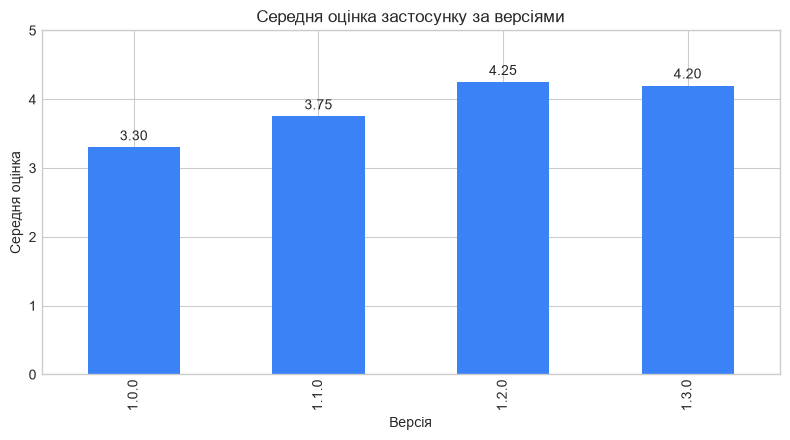

In [6]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))
rating_by_version.plot(kind="bar", color="#3b82f6", ax=ax)
ax.set_title("Середня оцінка застосунку за версіями")
ax.set_xlabel("Версія")
ax.set_ylabel("Середня оцінка")
ax.set_ylim(0, 5)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
fig.tight_layout()
fig.savefig("chart_ratings.png", dpi=180, bbox_inches="tight")
plt.show()

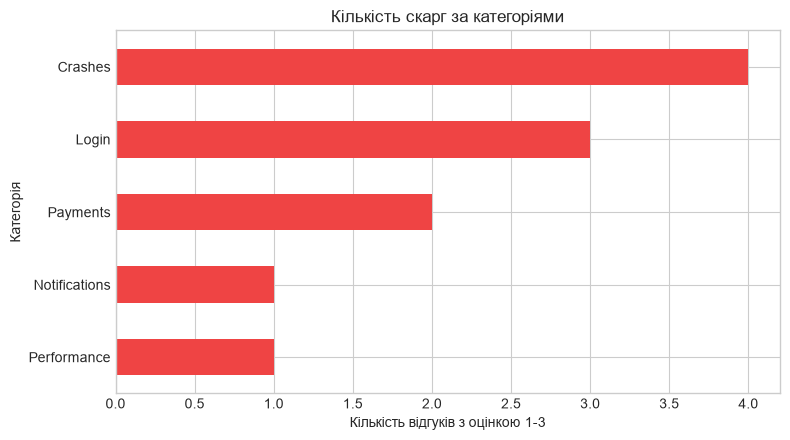

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
complaints_by_category["complaints"].sort_values().plot(kind="barh", color="#ef4444", ax=ax)
ax.set_title("Кількість скарг за категоріями")
ax.set_xlabel("Кількість відгуків з оцінкою 1-3")
ax.set_ylabel("Категорія")
fig.tight_layout()
fig.savefig("chart_complaints.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Журнал AI

**Запит A (генерація коду):** «Напиши pandas-код, який для DataFrame `df` з полями `rating`, `category`, `version` обчислює середню оцінку за версіями й будує горизонтальну діаграму кількості скарг, де скарга має `rating <= 3`. Додай підписи осей і заголовки».

**Відповідь AI та застосування:** запропоновано використати `groupby`, булевий фільтр і `plot(kind="barh")`. Код перевірено власним запуском: таблиці мають очікувані поля, обидві діаграми побудовано, сума категорій скарг збігається з кількістю рядків у відфільтрованому DataFrame.

**Запит B (виправлення помилки):** «Поясни `KeyError: 'raiting'` у виразі `df['raiting'].mean()` і запропонуй безпечне виправлення».

**Відповідь AI та застосування:** у DataFrame немає стовпця `raiting`; це друкарська помилка. Перед виправленням перевірено `df.columns`, після чого назву змінено на `rating`.

In [8]:
# Демонстрація перевіреного виправлення помилки
print("Наявні стовпці:", list(df.columns))
print("Середня оцінка:", round(df["rating"].mean(), 2))

Наявні стовпці: ['review_id', 'rating', 'category', 'length', 'version']
Середня оцінка: 3.86


## 5. Висновки
У наборі з 36 синтетичних відгуків середня оцінка зростає від версії 1.0.0 до 1.3.0. Найбільше скарг зафіксовано в категорії `Crashes`, тому її доцільно перевірити першою. Фільтрація `rating <= 3` дала змогу відокремити негативні відгуки від нейтральних і позитивних. Результати перевірено повторним запуском усіх комірок без помилок.